# Customer Churn Analysis
**Author:** Ashik Dev A S
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn), Jupyter Notebook

A telecom company is losing customers. This notebook explores **7,043 customer records** to answer:

1. How many customers churn, and how much monthly revenue does that cost?
2. Which customer groups churn the most (contract, tenure, services, billing)?
3. What should the business do about it?

**Dataset:** IBM Telco Customer Churn sample (`data/Telco-Customer-Churn.csv`). Each row is one customer, with demographics, account details, subscribed services and whether they left in the last month (`Churn`).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import textwrap

pd.set_option("display.max_columns", 30)
IMG = Path("../images"); IMG.mkdir(exist_ok=True)

TEAL, CORAL, AMBER, GREY = "#2A7F8F", "#E05D5A", "#F2A541", "#8A9BA0"
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 100})

def save(fig, name):
    fig.savefig(IMG / name, dpi=120, bbox_inches="tight")

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data cleaning

Checks: duplicate customers, missing values, data types and category labels.

In [4]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values (as loaded):", df.isna().sum().sum())

# TotalCharges is stored as text because some cells are blank spaces
blank_total = (df["TotalCharges"].str.strip() == "")
print("Blank TotalCharges:", blank_total.sum())
df.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Duplicate customer IDs: 0
Missing values (as loaded): 0
Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


The 11 blank `TotalCharges` all belong to customers with **tenure = 0**: they signed up this month and have not been billed yet. The correct value is **0**, not a missing value to drop.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", "0"))

# Readable labels and a numeric churn flag
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Churned"] = (df["Churn"] == "Yes").astype(int)

# Tenure groups for analysis
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])

# Quick consistency check: TotalCharges should be roughly tenure x MonthlyCharges
ratio = (df["TotalCharges"] / (df["tenure"] * df["MonthlyCharges"])).replace([np.inf], np.nan)
print("TotalCharges / (tenure x monthly) - median:", round(ratio.median(), 3))
print("Cleaned shape:", df.shape, "| missing values:", df.isna().sum().sum())

TotalCharges / (tenure x monthly) - median: 1.0
Cleaned shape: (7043, 23) | missing values: 0


In [6]:
for col in ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport"]:
    print(col, "->", sorted(df[col].unique()))

Contract -> ['Month-to-month', 'One year', 'Two year']
InternetService -> ['DSL', 'Fiber optic', 'No']
PaymentMethod -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
OnlineSecurity -> ['No', 'No internet service', 'Yes']
TechSupport -> ['No', 'No internet service', 'Yes']


## 4. How big is the churn problem?

In [7]:
churn_rate = df["Churned"].mean()
churned = df["Churned"].sum()
lost_mrr = df.loc[df["Churned"] == 1, "MonthlyCharges"].sum()
total_mrr = df["MonthlyCharges"].sum()

print(f"Customers: {len(df):,}")
print(f"Churned: {churned:,} ({churn_rate:.1%})")
print(f"Monthly revenue lost to churn: ${lost_mrr:,.0f} of ${total_mrr:,.0f} ({lost_mrr/total_mrr:.1%})")

Customers: 7,043
Churned: 1,869 (26.5%)
Monthly revenue lost to churn: $139,131 of $456,117 (30.5%)


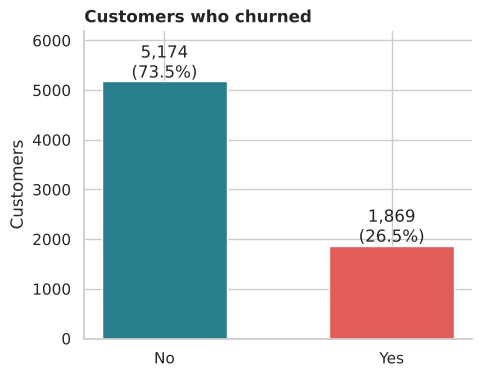

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Churn"].value_counts()
ax.bar(counts.index, counts.values, color=[TEAL, CORAL], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 80, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_title("Customers who churned"); ax.set_ylabel("Customers"); ax.set_ylim(0, 6200)
save(fig, "01_churn_overview.png"); plt.show()

## 5. Which customers churn?

A helper function gives the churn rate and customer count for any column.

In [9]:
def churn_by(col):
    t = (df.groupby(col, observed=True)["Churned"]
           .agg(customers="size", churned="sum", churn_rate="mean")
           .sort_values("churn_rate", ascending=False))
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t

def churn_bar(col, title, fname, order=None, ax=None):
    t = df.groupby(col, observed=True)["Churned"].mean()
    if order is not None: t = t.reindex(order)
    show = ax is None
    if ax is None: fig, ax = plt.subplots(figsize=(6, 3.6))
    colors = [CORAL if v > churn_rate else TEAL for v in t.values]
    labels = [textwrap.fill(str(x).replace(" (automatic)", " (auto)"), 14) for x in t.index]
    ax.bar(labels, t.values, color=colors, width=0.6)
    ax.grid(axis="x", visible=False)
    ax.axhline(churn_rate, ls="--", color=GREY, lw=1)
    ax.text(len(t) - 0.5, churn_rate + 0.01, f"avg {churn_rate:.0%}", ha="right", color=GREY, fontsize=9)
    for i, v in enumerate(t.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=10)
    ax.set_title(title); ax.set_ylabel("Churn rate"); ax.set_ylim(0, max(t.values) * 1.25)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:.0%}"))
    if show:
        save(ax.figure, fname); plt.show()

### 5.1 Contract type

In [10]:
churn_by("Contract")

,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


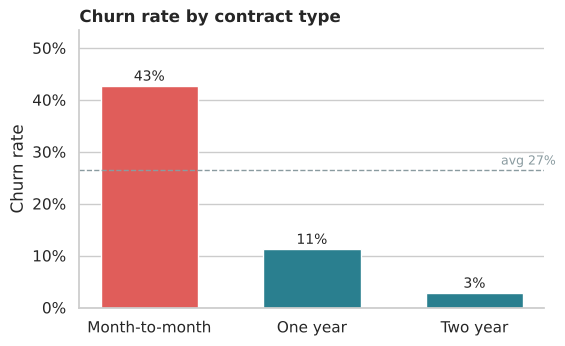

Share of all churners on month-to-month contracts: 88.6%


In [11]:
churn_bar("Contract", "Churn rate by contract type", "02_churn_by_contract.png",
          order=["Month-to-month", "One year", "Two year"])
m2m_share = df.loc[df["Churned"] == 1, "Contract"].eq("Month-to-month").mean()
print(f"Share of all churners on month-to-month contracts: {m2m_share:.1%}")

**Month-to-month customers churn at 42.7%**, against 11.3% on one-year and 2.8% on two-year contracts. They make up **88.6% of all churners**.

### 5.2 Tenure

In [12]:
churn_by("TenureGroup").sort_index()

,customers,churned,churn_rate
TenureGroup,,,
0-12 months,2186,1037,47.4
13-24 months,1024,294,28.7
25-48 months,1594,325,20.4
49-72 months,2239,213,9.5


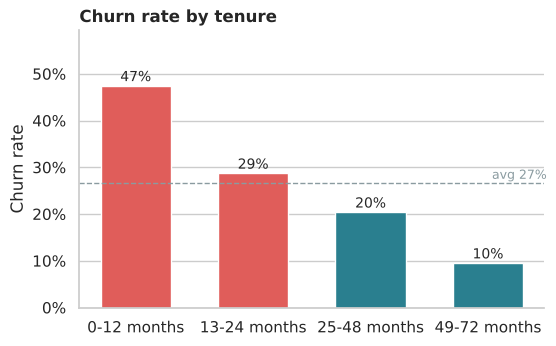

In [13]:
churn_bar("TenureGroup", "Churn rate by tenure", "03_churn_by_tenure.png",
          order=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])

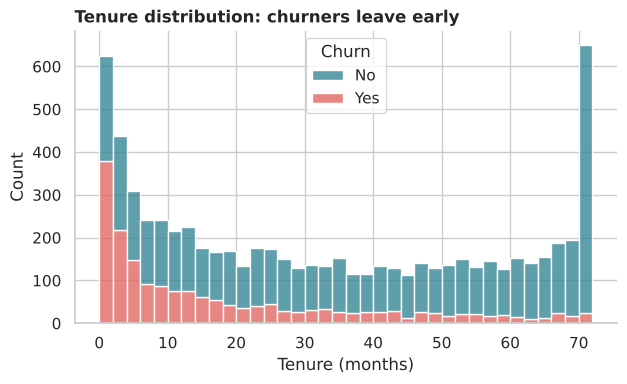

Churn
No     38.0
Yes    10.0
Name: median tenure (months), dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack",
             palette={"No": TEAL, "Yes": CORAL}, ax=ax)
ax.set_title("Tenure distribution: churners leave early"); ax.set_xlabel("Tenure (months)")
save(fig, "04_tenure_distribution.png"); plt.show()
print(df.groupby("Churn")["tenure"].median().rename("median tenure (months)"))

Risk is highest in the **first year (47.4% churn)** and falls steadily with tenure, to 9.5% after four years. The median churner leaves after **10 months**; the median loyal customer has stayed 38.

### 5.3 Monthly charges

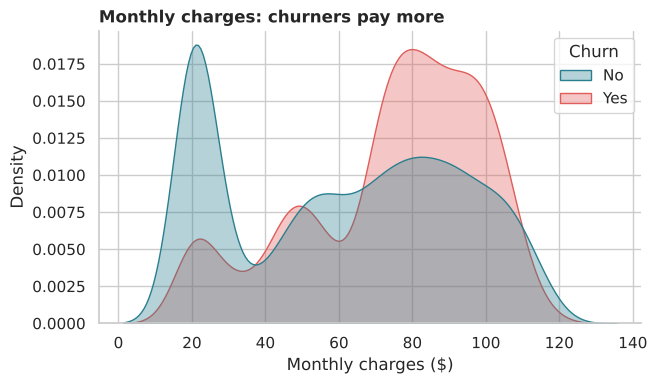

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False,
            palette={"No": TEAL, "Yes": CORAL}, alpha=0.35, ax=ax)
ax.set_title("Monthly charges: churners pay more"); ax.set_xlabel("Monthly charges ($)")
save(fig, "05_monthly_charges.png"); plt.show()
df.groupby("Churn")["MonthlyCharges"].describe().round(2)

Churners pay more per month (median **$79.65** vs $64.43). Their charges cluster at **$70–$110**, the price range of fibre-optic plans.

### 5.4 Services and billing

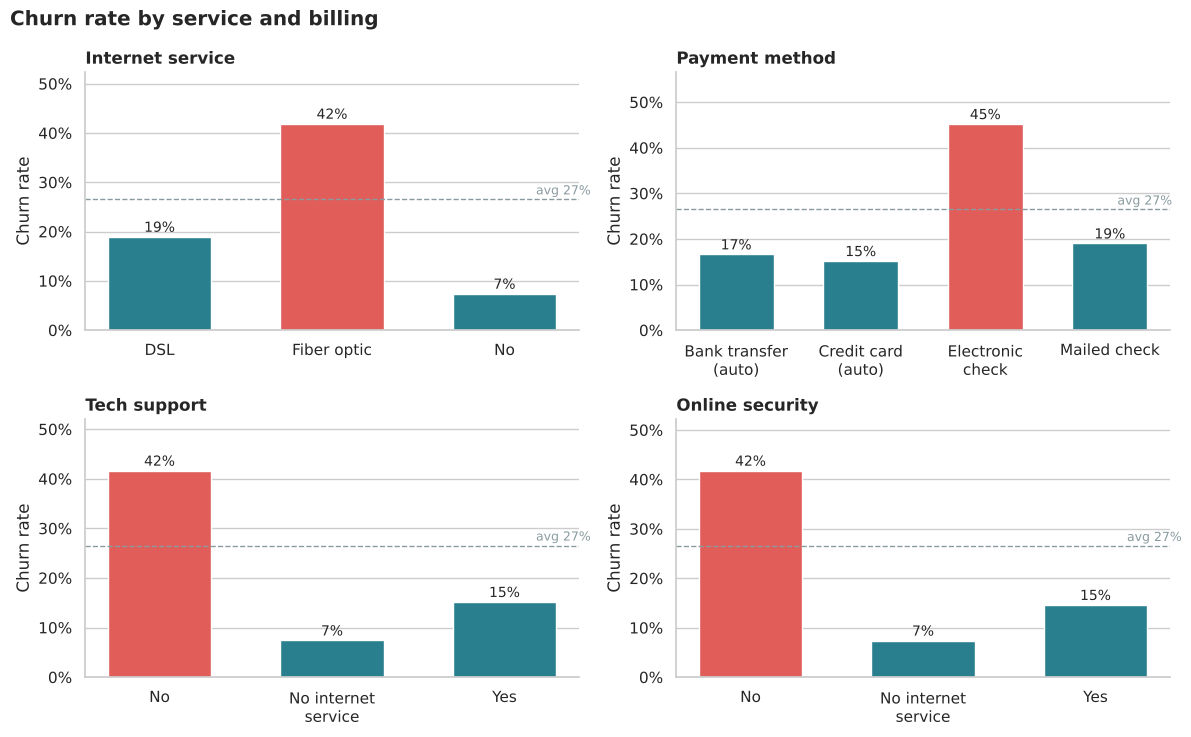

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
churn_bar("InternetService", "Internet service", None, ax=axes[0, 0])
churn_bar("PaymentMethod", "Payment method", None, ax=axes[0, 1])
churn_bar("TechSupport", "Tech support", None, ax=axes[1, 0])
churn_bar("OnlineSecurity", "Online security", None, ax=axes[1, 1])
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Churn rate by service and billing", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "06_services_and_billing.png"); plt.show()

In [17]:
summary = pd.concat({c: churn_by(c) for c in
                     ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]})
summary

customers  churned  churn_rate
InternetService  Fiber optic                     3096     1297        41.9
                 DSL                             2421      459        19.0
                 No                              1526      113         7.4
PaymentMethod    Electronic check                2365     1071        45.3
                 Mailed check                    1612      308        19.1
                 Bank transfer (automatic)       1544      258        16.7
                 Credit card (automatic)         1522      232        15.2
TechSupport      No                              3473     1446        41.6
                 Yes                             2044      310        15.2
                 No internet service             1526      113         7.4
OnlineSecurity   No                              3498     1461        41.8
                 Yes                             2019      295        14.6
                 No internet service             1526      113         7.4
PaperlessBilling Yes                             4171     1400        33.6
                 No                              2872      469        16.3

- **Fibre-optic** customers churn at **41.9%**, more than double DSL (19.0%).
- Customers paying by **electronic check** churn at **45.3%**, about three times the rate of automatic card or bank payments (15–17%).
- Customers **without tech support or online security** churn at about 42%, against about 15% for those who have them.

### 5.5 Customer profile

In [18]:
pd.concat({c: churn_by(c) for c in ["SeniorCitizen", "Partner", "Dependents"]})

customers  churned  churn_rate
SeniorCitizen Yes       1142      476        41.7
              No        5901     1393        23.6
Partner       No        3641     1200        33.0
              Yes       3402      669        19.7
Dependents    No        4933     1543        31.3
              Yes       2110      326        15.5

Senior citizens (41.7%) and customers without a partner (33.0%) or dependents (31.3%) churn more than average.

## 6. Combining the two biggest drivers

What happens when a customer is both new and on a month-to-month contract?

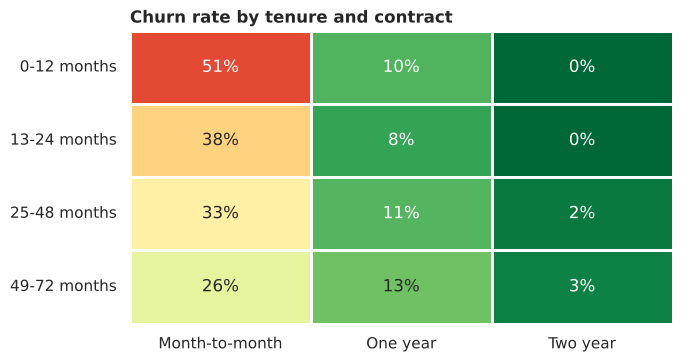

New (<=12 months) month-to-month customers: 1,994 (28.3% of base), churn rate 51.4%, 1,024 churners = 54.8% of all churn


In [19]:
pivot = df.pivot_table(index="TenureGroup", columns="Contract", values="Churned", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlGn_r", vmin=0, vmax=0.6, cbar=False, ax=ax, linewidths=1)
ax.set_title("Churn rate by tenure and contract"); ax.set_ylabel(""); ax.set_xlabel("")
save(fig, "07_tenure_contract_heatmap.png"); plt.show()

risk = df[(df["Contract"] == "Month-to-month") & (df["tenure"] <= 12)]
print(f"New (<=12 months) month-to-month customers: {len(risk):,} "
      f"({len(risk)/len(df):.1%} of base), churn rate {risk['Churned'].mean():.1%}, "
      f"{risk['Churned'].sum():,} churners = {risk['Churned'].sum()/churned:.1%} of all churn")

## 7. Correlation of numeric features with churn

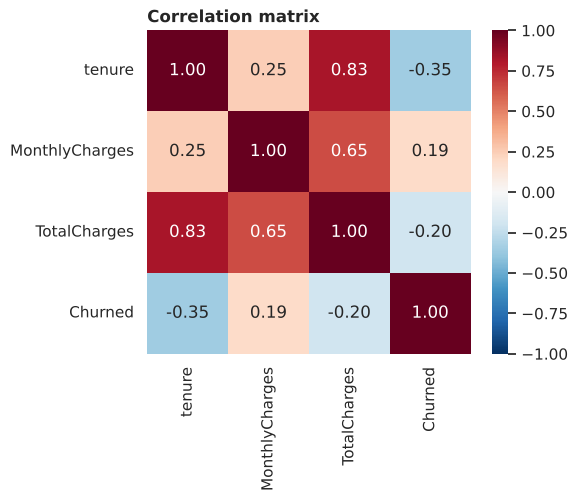

In [20]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "Churned"]]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Correlation matrix")
save(fig, "08_correlation.png"); plt.show()

Tenure has the strongest (negative) link with churn (**-0.35**). Monthly charges have a positive link (**+0.19**). Correlation is not causation, but this matches the group-level findings above.

## 8. Key findings

| # | Finding | Evidence |
|---|---|---|
| 1 | **26.5% of customers churned**, costing about **$139K a month** (30.5% of monthly revenue) | 1,869 of 7,043 customers |
| 2 | **Contract type is the biggest driver** | Month-to-month 42.7% vs two-year 2.8%; 88.6% of churners are month-to-month |
| 3 | **The first year is the danger zone** | 47.4% churn at 0–12 months vs 9.5% after 4 years; median churner leaves at 10 months |
| 4 | **Fibre-optic customers churn heavily** | 41.9% vs 19.0% for DSL; churners pay more per month |
| 5 | **Electronic-check payers churn about 3x more** | 45.3% vs 15–17% on automatic payments |
| 6 | **Support add-ons protect retention** | No tech support 41.6% vs 15.2% with it |

## 9. Recommendations

1. **Convert month-to-month customers to annual plans**, for example with a discount or bonus service for switching in their first 3 months.
2. **Run a first-year onboarding programme** with check-ins at months 1, 3 and 6. Most churn happens before month 12.
3. **Bundle tech support and online security** free for the first 6 months on fibre plans.
4. **Nudge electronic-check payers to autopay** with a small monthly credit.
5. **Investigate fibre-optic satisfaction** (price, speed, outages). It is the highest-revenue product and also the highest-churn one.

*Next step:* build a churn-prediction model (logistic regression or random forest) to score at-risk customers each month.